In [1]:
import os
import shutil
import pandas as pd
from glob import glob
from tqdm.notebook import tqdm
import numpy as np
from PIL import Image, ImageOps, ImageFilter
import cv2
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from skimage import io
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances
import math
import lightning as L
from annoy import AnnoyIndex
from collections import Counter
import torch
from torchvision import tv_tensors

# 4 Application pipeline

This notebuc descrebes the final state of the proposed data processing pipeline in a scope of an environmental research.

In [2]:
from common.configuration import ModelPath, DatasetPath, species_invasive, species_native
from common.img_utils import object_separation_stage, object_detection_stage

## Segmentation model

In [3]:
from Instance_Segmentation import SegmentationModelWrapper
from Instance_Segmentation.train_model import get_model_instance_segmentation, get_transform



from skimage import morphology
from scipy import ndimage as ndi

In [4]:
def erode(cycles, image):
    for _ in range(cycles):
         image = image.filter(ImageFilter.MinFilter(3))
    return image


def dilate(cycles, image):
    for _ in range(cycles):
         image = image.filter(ImageFilter.MaxFilter(3))
    return image
    
def smooth_edges(img):
    img_gray = img.convert("L")
    threshold = 0
    img_threshold = img_gray.point(
        lambda x: 255 if x > threshold else 0
    )
    step_1 = erode(3, img_threshold)
    mask = erode(1, step_1)
    mask = mask.convert("L")
    mask = mask.filter(ImageFilter.BoxBlur(3))
    blank = img.point(lambda _: 0)
    segmented = Image.composite(img, blank, mask)
    return segmented

def smooth_mask(img):
    img_gray = img.convert("L")
    threshold = 0
    img_threshold = img_gray.point(
        lambda x: 255 if x > threshold else 0
    )
    step_1 = erode(3, img_threshold)
    mask = erode(1, step_1)
    mask = mask.convert("L")
    mask = mask.filter(ImageFilter.BoxBlur(3))
    mask = mask.point(
        lambda x: 255 if x > threshold else 0
    )
    mask = dilate(3, mask)
    return mask

In [5]:
from torchvision.io import read_image 

segmentation_model = SegmentationModelWrapper(ModelPath.instance_segmentation)

### Real-world samples dataset

 Plot some samples to test dataset

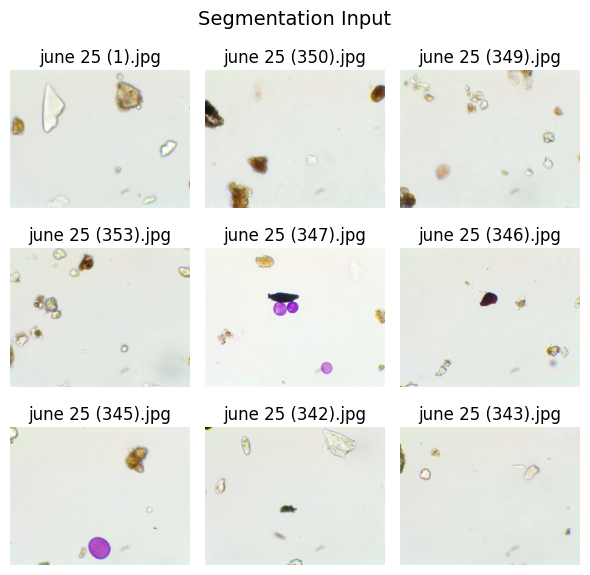

In [6]:
# segmentation_input_dir = os.path.join(DatasetPath.real_historical_samples, "april 10")
# segmentation_input_dir = r"F:\Research\Pollen Cls\Pollen-Analyzer\Dataset\pollen_dataset_2025_02_05\historical_train"
# segmentation_input_dir = r"Dataset\pollen_dataset_2025_02_05\samples\Alnus"
segmentation_input_dir = DatasetPath.real_historical_samples
images = glob(os.path.join(segmentation_input_dir, "*" ,"*.jpg"))

# Plot some samples
samples = images[0:9]
n = math.ceil(len(samples) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n*2, n*2))
for ax, img_path in zip(axs.flatten(), samples):
    image_rgb = io.imread(img_path)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path))
for ax in axs.flatten()[len(samples):]:
    ax.set_visible(False)
fig.suptitle('Segmentation Input', fontsize=14)
plt.tight_layout()
plt.show()

### Process all images

In [7]:
segmentation_output_dir = "Save/app_pipeline/segmentation_output_sample"
# segmentation_output_dir = "Save/app_pipeline/segmentation_output_hist_train"


In [8]:
if os.path.exists(segmentation_output_dir):
    shutil.rmtree(segmentation_output_dir)
os.makedirs(segmentation_output_dir, exist_ok=True)

In [9]:
for image_path in tqdm(images):
    segmentation_model(image_path=image_path, output_dir=segmentation_output_dir)

  0%|          | 0/6338 [00:00<?, ?it/s]

d:\Research\Pollen Cls\Pollen-Analyzer\.venv\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
d:\Research\Pollen Cls\Pollen-Analyzer\.venv\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


KeyboardInterrupt: 

### Plot some objs

In [ ]:

from common.img_utils import clean_background

all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)[0:100]
n = math.ceil(len(all_obj_images) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n, n))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    # image_rgb = clean_background(image_rgb)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path), fontsize=6)
for ax in axs.flatten()[len(all_obj_images):]:
    ax.set_visible(False)

fig.suptitle('Segmentation results', fontsize=14)
plt.tight_layout()
plt.show()

## OSC Model

In [ ]:
from common.osc_classification import OpenSetClassificationModel, extract_features

classification_model = OpenSetClassificationModel(20)
classification_model.load_state_dict(torch.load(ModelPath.osc_classification))
classification_model.to("cuda")
classification_model.eval()


### Fill DB using OSC Model and reference dataset

In [ ]:
from common.configuration import DatasetPath, ModelPath, species_native, species_label_map_all, species_classes_map_all

### Process real-world samples

In [ ]:
from common.osc_classification import distance_to_scores, scores_to_class

In [ ]:
species_classes_map_all

In [ ]:
model_class_to_c_number_remap = {}
for i, c in enumerate(species_native):
    model_class_to_c_number_remap[i] = species_classes_map_all[c]

def prediction_to_class_name(prediction):
    predicted_c_number = model_class_to_c_number_remap.get(prediction, -1)
    return species_label_map_all[predicted_c_number]

pred_labels = {}
embeddings_data = []
predicted_labels = []

all_obj_images = glob(os.path.join(
    segmentation_output_dir,  "**", "*.png"), recursive=True)

for img_path in tqdm(all_obj_images):
    img = Image.open(img_path)#.convert("RGB")
    # img = smooth_edges(img)
    features, pred_distances = extract_features(img, classification_model)
    vector = features[0]
    # classification by model
    scores = distance_to_scores(pred_distances)
    prediction = scores_to_class(scores, 8)
    predict_str = [prediction_to_class_name(l.item()) for l in prediction.cpu()]

    pred_class = predict_str[0]
    if pred_class in pred_labels:
        pred_labels[pred_class] += 1
    else:
        pred_labels[pred_class] = 1

    embeddings_data.append(vector.cpu().numpy())
    predicted_label = model_class_to_c_number_remap.get(
        prediction.cpu().numpy()[0], -1)
    predicted_labels.append(predicted_label)

Plot T-SNE for real-world images

In [ ]:
# TSNE
vectors = np.array(embeddings_data)
tsne = TSNE(n_components=2, random_state=45, perplexity=15, metric="euclidean", n_iter=2000, n_jobs=-1, early_exaggeration=15)#cosine
vectors_2d = tsne.fit_transform(vectors)

plt.figure(figsize=(5, 5))
plt.scatter(vectors_2d[:,0], vectors_2d[:,1], c=predicted_labels, alpha=0.6)

plt.title("t-SNE visualization of image features")
plt.tight_layout()
plt.show()

In [ ]:
plt.hist(predicted_labels, bins=np.arange(21)-1,align="left")
plt.xticks(np.arange(21)-1)
plt.show()

In [ ]:
pred_labels

### Compare with manual data

In [ ]:
excel_path = os.path.join(DatasetPath.real_historical_samples, "manual_analysis.xlsx")
df = pd.ExcelFile(excel_path)

In [ ]:
sheet_data = df.parse(df.sheet_names[0])
sheet_data = sheet_data.rename(columns={"Populus": "Populus tremula"})
sheet_data.head(4)

In [ ]:
from common.stats import calculate_confusion_matrix, plot_confusion_matrix

In [ ]:
def test_sample_data(true_labels, pred_labels, all_classes):
    print("---Sample test---")
    print(f"True Total objets: {sum(true_labels.values())}, data: {true_labels}")
    print("-" * 10)
    print(f"Pred Total objets: {sum(pred_labels.values())}, data: {pred_labels}")
    confusion_matrices_df = calculate_confusion_matrix(true_labels, pred_labels, all_classes)
    plot_confusion_matrix(confusion_matrices_df.iloc[:, 0:3])
    for k in true_labels.keys():
        if true_labels[k] != 0:
            print(k, round(confusion_matrices_df["TP"].to_dict().get(k, 0) / true_labels[k], 3))

In [ ]:
for i in range(1):
    output_dir = str(sheet_data.iloc[i][0])
    true_labels = sheet_data.iloc[i][1:].to_dict()
    pred_labels = {}

    all_obj_images = glob(os.path.join(segmentation_output_dir,
                                       output_dir, 
                                       "*.png"), recursive=True)
    for img_path in tqdm(all_obj_images):
        img = Image.open(img_path)#.convert("RGB")
        # img = smooth_edges(img)
        features, pred_distances = extract_features(img, classification_model)
        vector = features[0]
        # classification by model
        scores = distance_to_scores(pred_distances)
        prediction = scores_to_class(scores, 8.0)
        predict_str = [prediction_to_class_name(l.item()) for l in prediction.cpu()]

        pred_class = predict_str[0]
        if pred_class in pred_labels:
            pred_labels[pred_class] += 1
        else:
            pred_labels[pred_class] = 1
    all_classes = set(true_labels.keys()).union(set(pred_labels.keys()))
    test_sample_data(true_labels, pred_labels, all_classes)